# School-age digital connectivity: data cleaning and exploration

Cleaning and exploring a dataset on the share of school-age children with an internet connection at home, by country, income group, residence and household wealth. The data is a variant of UNICEF's global database on school-age digital connectivity.

See the README for the data source, the cleaning decisions and the main findings.

## 1. Data preparation

In [1]:
# Importing Pandas to create a Pandas Dataframe
import pandas as pd
import numpy as np

In [2]:
# Using pandas to read the csv file
school_df = pd.read_csv('data/school_age_digital_connectivity_raw.csv', sep=',', decimal='.', header=1)

In [3]:
# Check that the dataframe has been read correctly
school_df.head()

,ISO3,Countries and areas,Region,Sub-region,Income Group,Total,Rural (Residence),Urban (Residence),Poorest (Wealth quintile),Richest (Wealth quintile),Data source,Time period
0,DZA,Algeria,MENA,MENA,Upper middle income (UM),24%,9%,32%,1%,77%,Multiple Indicator Cluster Survey,2018-19
1,AGO,Angola,SSA,ESA,Lower middle income (LM),17%,2%,24%,0%,62%,Demographic and Health Survey,2015-16
2,ARM,Armenia,ECA,EECA,Upper middle income (UM),81%,71%,88%,47%,99%,Demographic and Health Survey,2015-16
3,BGD,Bangladesh,SA,SA,Lower middle income (LM),37%,33%,52%,9%,76%,Multiple Indicator Cluster Survey,2019
4,BRB,Barbados,LAC,LAC,High income (H),66%,61%,69%,10%,98%,Multiple Indicator Cluster Survey,2012


In [4]:
# Observe the size and shape of the dataframe.
# We can see there are 78 rows and 12 columns.
# There appear to be different datatypes and some missing values.
# When opening the csv file in Excel and in Jupyter notebook, there appears to be whitespace in row 27 (Georgia)
school_df

,ISO3,Countries and areas,Region,Sub-region,Income Group,Total,Rural (Residence),Urban (Residence),Poorest (Wealth quintile),Richest (Wealth quintile),Data source,Time period
0,DZA,Algeria,MENA,MENA,Upper middle income (UM),24%,9%,32%,1%,77%,Multiple Indicator Cluster Survey,2018-19
1,AGO,Angola,SSA,ESA,Lower middle income (LM),17%,2%,24%,0%,62%,Demographic and Health Survey,2015-16
2,ARM,Armenia,ECA,EECA,Upper middle income (UM),81%,71%,88%,47%,99%,Demographic and Health Survey,2015-16
3,BGD,Bangladesh,SA,SA,Lower middle income (LM),37%,33%,52%,9%,76%,Multiple Indicator Cluster Survey,2019
4,BRB,Barbados,LAC,LAC,High income (H),66%,61%,69%,10%,98%,Multiple Indicator Cluster Survey,2012
...,...,...,...,...,...,...,...,...,...,...,...,...
73,UGA,Uganda,SSA,ESA,Low income (L),0%,0%,2%,0%,2%,LSMS,2015
74,UKR,Ukraine,ECA,EECA,Lower middle income (LM),71%,NaN,71%,NaN,NaN,STEP Skills Measurement Household Survey 2013 ...,2013
75,UZB,Uzbekistan,ECA,EECA,Lowerr middle income (LM),19%,16%,29%,1%,69%,UNICEF Nutrition Survey 2017,2017
76,ZMB,Zambia,SSA,ESA,Lower middle income (LM),6%,2%,13%,0%,28%,Demographic and Health Survey,2018-19


In [5]:
# There appears to be three rows of data for Turkey.
school_df['ISO3'].value_counts()

TUR    3
DZA    1
MAR    1
STP    1
LCA    1
      ..
GMB    1
EGY    1
DOM    1
DJI    1
ZWE    1
Name: ISO3, Length: 76, dtype: int64

In [6]:
# On further investigation we can see the Turkey rows are duplicates and need to be merged into one.
school_df.loc[school_df['ISO3'] == 'TUR']

,ISO3,Countries and areas,Region,Sub-region,Income Group,Total,Rural (Residence),Urban (Residence),Poorest (Wealth quintile),Richest (Wealth quintile),Data source,Time period
69,TUR,Turkey,ECA,EECA,Upper middle income (UM),36%,14%,43%,2%,90%,Demographic and Health Survey,2013
70,TUR,Turkey,ECA,EECA,Upper middle income (UM),36%,14%,43%,2%,90%,Demographic and Health Survey,2013
71,TUR,Turkey,ECA,EECA,Upper middle income (UM),36%,14%,43%,2%,90%,Demographic and Health Survey,2013


In [7]:
# Removing duplicates as per https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.drop_duplicates.html
school_df = school_df.drop_duplicates()

In [8]:
# We can now see there is only ONE Turkey row
school_df.loc[school_df['ISO3'] == 'TUR']

,ISO3,Countries and areas,Region,Sub-region,Income Group,Total,Rural (Residence),Urban (Residence),Poorest (Wealth quintile),Richest (Wealth quintile),Data source,Time period
69,TUR,Turkey,ECA,EECA,Upper middle income (UM),36%,14%,43%,2%,90%,Demographic and Health Survey,2013


In [9]:
# There appear to be no problems with the 'Region' variable
school_df['Region'].value_counts()

SSA     27
LAC     15
ECA     14
EAP      8
MENA     6
SA       6
Name: Region, dtype: int64

In [10]:
# There appear to be no problems with the 'Region' variable
school_df['Sub-region'].value_counts()

WCA     16
LAC     15
EECA    14
ESA     11
EAP      8
MENA     6
SA       6
Name: Sub-region, dtype: int64

In [11]:
# There appears to be 2 errors in relation to the income group data 
# 1. Some 'white spaces' before 'Upper middle income (UM)'in the 'Income Group'.
# 2. A typo for 'Lower middle income (LM)' (Lower spelt 'Lowerr')
school_df['Income Group'].value_counts()

Upper middle income (UM)        27
Lower middle income (LM)        26
Low income (L)                  16
High income (H)                  5
    Upper middle income (UM)     1
Lowerr middle income (LM)        1
Name: Income Group, dtype: int64

In [12]:
# Use strip function to remove white space. By applying this function to every column with 'string' values, any other whitespace that has been undetected is now eliminated.
school_df['Income Group'] = school_df['Income Group'].str.lstrip()
school_df['ISO3'] = school_df['ISO3'].str.lstrip()
school_df['Countries and areas'] = school_df['Countries and areas'].str.lstrip()
school_df['Region'] = school_df['Region'].str.lstrip()
school_df['Sub-region'] = school_df['Sub-region'].str.lstrip()
school_df['Data source'] = school_df['Data source'].str.lstrip()

In [13]:
# Ensure 'Lowerr middle income' is spelt correctly
school_df['Income Group'].replace('Lowerr middle income (LM)', 'Lower middle income (LM)', inplace = True)

In [14]:
# Check that spelling error has been corrected.
# Check white space has been removed.
# Both problems are now resolved for 'Income Group'
school_df['Income Group'].value_counts()

Upper middle income (UM)    28
Lower middle income (LM)    27
Low income (L)              16
High income (H)              5
Name: Income Group, dtype: int64

In [15]:
#Columns: 'Total', 'Rural (Residence)', 'Urban (Residence)', 'Poorest (Wealth quintile)', 'Richest (Wealth quintile)' are all listed as %. 
#There are some values with typos with double %%. To deal with this, we will convert all numbers to floats and put % in the heading. This will maintain good user readabillity as well as make the data more compatible for passing through a model.

In [16]:
school_df['Total'].value_counts()

24%     3
17%     3
4%      3
9%      3
3%      3
5%      3
2%      3
71%     2
32%     2
19%     2
44%     2
6%      2
0%      2
70%     2
1%      2
37%     2
50%     1
18%     1
7%      1
47%     1
46%     1
31%     1
89%     1
36%     1
48%     1
39%     1
91%     1
94%     1
23%     1
92%     1
82%     1
13%     1
38%     1
41%     1
11%     1
81%     1
66%     1
12%     1
59%     1
83%     1
76%     1
86%     1
57%     1
36%%    1
72%     1
65%     1
85%     1
21%     1
49%     1
78%     1
51%     1
74%     1
26%     1
Name: Total, dtype: int64

In [17]:
# Strip '%' from values (https://stackoverflow.com/questions/25669588/convert-percent-string-to-float-in-pandas-read-csv)
school_df['Total'] = school_df['Total'].str.rstrip('%').astype('float')

In [18]:
school_df.rename(columns = {'Total':'Total (%)'}, inplace = True)

In [19]:
# We can see now, the 'Total' column now has float values and the heading contains (%) symbol.
# The same principal will be applied to the rest of the afformentioned/subsequent columns.
school_df

,ISO3,Countries and areas,Region,Sub-region,Income Group,Total (%),Rural (Residence),Urban (Residence),Poorest (Wealth quintile),Richest (Wealth quintile),Data source,Time period
0,DZA,Algeria,MENA,MENA,Upper middle income (UM),24.0,9%,32%,1%,77%,Multiple Indicator Cluster Survey,2018-19
1,AGO,Angola,SSA,ESA,Lower middle income (LM),17.0,2%,24%,0%,62%,Demographic and Health Survey,2015-16
2,ARM,Armenia,ECA,EECA,Upper middle income (UM),81.0,71%,88%,47%,99%,Demographic and Health Survey,2015-16
3,BGD,Bangladesh,SA,SA,Lower middle income (LM),37.0,33%,52%,9%,76%,Multiple Indicator Cluster Survey,2019
4,BRB,Barbados,LAC,LAC,High income (H),66.0,61%,69%,10%,98%,Multiple Indicator Cluster Survey,2012
...,...,...,...,...,...,...,...,...,...,...,...,...
73,UGA,Uganda,SSA,ESA,Low income (L),0.0,0%,2%,0%,2%,LSMS,2015
74,UKR,Ukraine,ECA,EECA,Lower middle income (LM),71.0,NaN,71%,NaN,NaN,STEP Skills Measurement Household Survey 2013 ...,2013
75,UZB,Uzbekistan,ECA,EECA,Lower middle income (LM),19.0,16%,29%,1%,69%,UNICEF Nutrition Survey 2017,2017
76,ZMB,Zambia,SSA,ESA,Lower middle income (LM),6.0,2%,13%,0%,28%,Demographic and Health Survey,2018-19


In [20]:
# In order to avoid any errors, unwanted white space will be removed from headers
school_df.columns = school_df.columns.str.strip()

In [21]:
school_df['Rural (Residence)'] = school_df['Rural (Residence)'].str.rstrip('%').astype('float')

In [22]:
school_df.rename(columns = {'Rural (Residence)':'Rural (Residence) (%)'}, inplace = True)

In [23]:
school_df['Urban (Residence)'] = school_df['Urban (Residence)'].str.rstrip('%').astype('float')


In [24]:
school_df.rename(columns = {'Urban (Residence)':'Urban (Residence) (%)'}, inplace = True)

In [25]:
school_df['Poorest (Wealth quintile)'] = school_df['Poorest (Wealth quintile)'].str.rstrip('%').astype('float')

In [26]:
school_df.rename(columns = {'Poorest (Wealth quintile)':'Poorest (Wealth quintile) (%)'}, inplace = True)

In [27]:
school_df['Richest (Wealth quintile)'] = school_df['Richest (Wealth quintile)'].str.rstrip('%').astype('float')

In [28]:
school_df.rename(columns = {'Richest (Wealth quintile)':'Richest (Wealth quintile) (%)'}, inplace = True)

In [29]:
# We can now see columns labelled 'Total', 'Rural (Residence)', 'Urban (Residence)', 'Poorest (Wealth quintile)', 'Richest (Wealth quintile) are all labelled appropriately and data has been converted to floats. 
school_df

,ISO3,Countries and areas,Region,Sub-region,Income Group,Total (%),Rural (Residence) (%),Urban (Residence) (%),Poorest (Wealth quintile) (%),Richest (Wealth quintile) (%),Data source,Time period
0,DZA,Algeria,MENA,MENA,Upper middle income (UM),24.0,9.0,32.0,1.0,77.0,Multiple Indicator Cluster Survey,2018-19
1,AGO,Angola,SSA,ESA,Lower middle income (LM),17.0,2.0,24.0,0.0,62.0,Demographic and Health Survey,2015-16
2,ARM,Armenia,ECA,EECA,Upper middle income (UM),81.0,71.0,88.0,47.0,99.0,Demographic and Health Survey,2015-16
3,BGD,Bangladesh,SA,SA,Lower middle income (LM),37.0,33.0,52.0,9.0,76.0,Multiple Indicator Cluster Survey,2019
4,BRB,Barbados,LAC,LAC,High income (H),66.0,61.0,69.0,10.0,98.0,Multiple Indicator Cluster Survey,2012
...,...,...,...,...,...,...,...,...,...,...,...,...
73,UGA,Uganda,SSA,ESA,Low income (L),0.0,0.0,2.0,0.0,2.0,LSMS,2015
74,UKR,Ukraine,ECA,EECA,Lower middle income (LM),71.0,NaN,71.0,NaN,NaN,STEP Skills Measurement Household Survey 2013 ...,2013
75,UZB,Uzbekistan,ECA,EECA,Lower middle income (LM),19.0,16.0,29.0,1.0,69.0,UNICEF Nutrition Survey 2017,2017
76,ZMB,Zambia,SSA,ESA,Lower middle income (LM),6.0,2.0,13.0,0.0,28.0,Demographic and Health Survey,2018-19


In [30]:
# Finally, the missing values must be dealt with. 
# In this dataset, it is apparent that columns 'Rural(Residence) (%)', 'Poorest (Wealth quintile) (%)', 'Richest (Wealth quintile) (%)' all have missing values
# To counter this, the mean of the column will be injected into the missing values.
print(school_df['ISO3'].isnull().value_counts())
print(school_df['Countries and areas'].isnull().value_counts())
print(school_df['Region'].isnull().value_counts())
print(school_df['Sub-region'].isnull().value_counts())
print(school_df['Income Group'].isnull().value_counts())
print(school_df['Total (%)'].isnull().value_counts())
print(school_df['Urban (Residence) (%)'].isnull().value_counts())
print(school_df['Rural (Residence) (%)'].isnull().value_counts())
print(school_df['Poorest (Wealth quintile) (%)'].isnull().value_counts())
print(school_df['Richest (Wealth quintile) (%)'].isnull().value_counts())
print(school_df['Data source'].isnull().value_counts())
print(school_df['Time period'].isnull().value_counts())

False    76
Name: ISO3, dtype: int64
False    76
Name: Countries and areas, dtype: int64
False    76
Name: Region, dtype: int64
False    76
Name: Sub-region, dtype: int64
False    76
Name: Income Group, dtype: int64
False    76
Name: Total (%), dtype: int64
False    76
Name: Urban (Residence) (%), dtype: int64
False    74
True      2
Name: Rural (Residence) (%), dtype: int64
False    70
True      6
Name: Poorest (Wealth quintile) (%), dtype: int64
False    69
True      7
Name: Richest (Wealth quintile) (%), dtype: int64
False    76
Name: Data source, dtype: int64
False    76
Name: Time period, dtype: int64


In [31]:
print(school_df['Rural (Residence) (%)'].skew())
print(school_df['Poorest (Wealth quintile) (%)'].skew())
print(school_df['Richest (Wealth quintile) (%)'].skew())

0.8115184543708142
1.3973390641744363
-0.524026730732908


In [32]:
school_df['Rural (Residence) (%)'] = school_df['Rural (Residence) (%)'].fillna(school_df['Rural (Residence) (%)'].median())
school_df['Rural (Residence) (%)'] = round(school_df['Rural (Residence) (%)'])

In [33]:
school_df['Poorest (Wealth quintile) (%)'] = school_df['Poorest (Wealth quintile) (%)'].fillna(school_df['Poorest (Wealth quintile) (%)'].median())
school_df['Poorest (Wealth quintile) (%)'] = round(school_df['Poorest (Wealth quintile) (%)'])

In [34]:
school_df['Richest (Wealth quintile) (%)'] = school_df['Richest (Wealth quintile) (%)'].fillna(school_df['Richest (Wealth quintile) (%)'].median())
school_df['Richest (Wealth quintile) (%)'] = round(school_df['Richest (Wealth quintile) (%)'])

In [35]:
# There is now no 'null' values or missing data.
print(school_df['ISO3'].isnull().value_counts())
print(school_df['Countries and areas'].isnull().value_counts())
print(school_df['Region'].isnull().value_counts())
print(school_df['Sub-region'].isnull().value_counts())
print(school_df['Income Group'].isnull().value_counts())
print(school_df['Total (%)'].isnull().value_counts())
print(school_df['Urban (Residence) (%)'].isnull().value_counts())
print(school_df['Rural (Residence) (%)'].isnull().value_counts())
print(school_df['Poorest (Wealth quintile) (%)'].isnull().value_counts())
print(school_df['Richest (Wealth quintile) (%)'].isnull().value_counts())
print(school_df['Data source'].isnull().value_counts())
print(school_df['Time period'].isnull().value_counts())

False    76
Name: ISO3, dtype: int64
False    76
Name: Countries and areas, dtype: int64
False    76
Name: Region, dtype: int64
False    76
Name: Sub-region, dtype: int64
False    76
Name: Income Group, dtype: int64
False    76
Name: Total (%), dtype: int64
False    76
Name: Urban (Residence) (%), dtype: int64
False    76
Name: Rural (Residence) (%), dtype: int64
False    76
Name: Poorest (Wealth quintile) (%), dtype: int64
False    76
Name: Richest (Wealth quintile) (%), dtype: int64
False    76
Name: Data source, dtype: int64
False    76
Name: Time period, dtype: int64


In [36]:
school_df

,ISO3,Countries and areas,Region,Sub-region,Income Group,Total (%),Rural (Residence) (%),Urban (Residence) (%),Poorest (Wealth quintile) (%),Richest (Wealth quintile) (%),Data source,Time period
0,DZA,Algeria,MENA,MENA,Upper middle income (UM),24.0,9.0,32.0,1.0,77.0,Multiple Indicator Cluster Survey,2018-19
1,AGO,Angola,SSA,ESA,Lower middle income (LM),17.0,2.0,24.0,0.0,62.0,Demographic and Health Survey,2015-16
2,ARM,Armenia,ECA,EECA,Upper middle income (UM),81.0,71.0,88.0,47.0,99.0,Demographic and Health Survey,2015-16
3,BGD,Bangladesh,SA,SA,Lower middle income (LM),37.0,33.0,52.0,9.0,76.0,Multiple Indicator Cluster Survey,2019
4,BRB,Barbados,LAC,LAC,High income (H),66.0,61.0,69.0,10.0,98.0,Multiple Indicator Cluster Survey,2012
...,...,...,...,...,...,...,...,...,...,...,...,...
73,UGA,Uganda,SSA,ESA,Low income (L),0.0,0.0,2.0,0.0,2.0,LSMS,2015
74,UKR,Ukraine,ECA,EECA,Lower middle income (LM),71.0,14.0,71.0,4.0,76.0,STEP Skills Measurement Household Survey 2013 ...,2013
75,UZB,Uzbekistan,ECA,EECA,Lower middle income (LM),19.0,16.0,29.0,1.0,69.0,UNICEF Nutrition Survey 2017,2017
76,ZMB,Zambia,SSA,ESA,Lower middle income (LM),6.0,2.0,13.0,0.0,28.0,Demographic and Health Survey,2018-19


In [37]:
# There appears to be no problems with this column, however as it is not needed for the exploration below, we can remove it from the dataframe.
school_df['Data source'].value_counts()

Multiple Indicator Cluster Survey                                                   43
Demographic and Health Survey                                                       16
The Japan Household Panel Survey                                                     1
STEP Skills Measurement Household Survey 2013 (Wave 1)                               1
LSMS                                                                                 1
STEP Skills Measurement Household Survey 2012 (Wave 1)                               1
Russia Longitudinal Monitoring Survey, 2018                                          1
Morocco Household and Youth Survey 2010                                              1
ENSANUT                                                                              1
STEP Skills Measurement Household Survey 2013 (Wave 2)                               1
SUSENAS                                                                              1
2015 Household Income, Expenditure and Cons

In [38]:
# Impossible values identified - 2076, 2562 - These years are in the future. Also, some values are listed as ranges and some values are listed as indivdual years.
# For the exploration below, we won't need to make amendments to these. Instead we will remove the entire column.
school_df['Time period'].value_counts()

2018       15
2018-19     8
2019        8
2017        8
2013        6
2012        4
2017-18     4
2015        4
2015-16     4
2014        3
2010        3
2016        2
2016-17     2
2011-12     1
2014-15     1
2076        1
2562        1
2011        1
Name: Time period, dtype: int64

In [39]:
# Now to remove any/all columns that are not needed for the exploration. 
school_df = school_df.drop(['ISO3','Time period', 'Data source', 'Region', 'Sub-region'], axis=1)

In [40]:
# The dataframe is almost ready for exploration. However to avoid data leakage, the countries an areas column needs to be removed as a feature.
school_df

,Countries and areas,Income Group,Total (%),Rural (Residence) (%),Urban (Residence) (%),Poorest (Wealth quintile) (%),Richest (Wealth quintile) (%)
0,Algeria,Upper middle income (UM),24.0,9.0,32.0,1.0,77.0
1,Angola,Lower middle income (LM),17.0,2.0,24.0,0.0,62.0
2,Armenia,Upper middle income (UM),81.0,71.0,88.0,47.0,99.0
3,Bangladesh,Lower middle income (LM),37.0,33.0,52.0,9.0,76.0
4,Barbados,High income (H),66.0,61.0,69.0,10.0,98.0
...,...,...,...,...,...,...,...
73,Uganda,Low income (L),0.0,0.0,2.0,0.0,2.0
74,Ukraine,Lower middle income (LM),71.0,14.0,71.0,4.0,76.0
75,Uzbekistan,Lower middle income (LM),19.0,16.0,29.0,1.0,69.0
76,Zambia,Lower middle income (LM),6.0,2.0,13.0,0.0,28.0


In [41]:
# Write dataframe object into csv file:
school_df.to_csv('data/school_connectivity_clean.csv', index=False)

In [42]:
clean_school_df = pd.read_csv('data/school_connectivity_clean.csv', index_col=0)

In [43]:
clean_school_df.to_csv('data/school_connectivity_clean.csv', index=False)
clean_school_df

,Income Group,Total (%),Rural (Residence) (%),Urban (Residence) (%),Poorest (Wealth quintile) (%),Richest (Wealth quintile) (%)
Countries and areas,,,,,,
Algeria,Upper middle income (UM),24.0,9.0,32.0,1.0,77.0
Angola,Lower middle income (LM),17.0,2.0,24.0,0.0,62.0
Armenia,Upper middle income (UM),81.0,71.0,88.0,47.0,99.0
Bangladesh,Lower middle income (LM),37.0,33.0,52.0,9.0,76.0
Barbados,High income (H),66.0,61.0,69.0,10.0,98.0
...,...,...,...,...,...,...
Uganda,Low income (L),0.0,0.0,2.0,0.0,2.0
Ukraine,Lower middle income (LM),71.0,14.0,71.0,4.0,76.0
Uzbekistan,Lower middle income (LM),19.0,16.0,29.0,1.0,69.0


## 2. Data exploration

### 2.1 Internet access by country income group

In [44]:
import matplotlib.pyplot as plt

In [45]:
# Obtain a basic understanding of the 'Total (%) column'
mask_total = clean_school_df['Total (%)']
mask_total.describe()

count    76.000000
mean     35.855263
std      29.561553
min       0.000000
25%       8.500000
50%      31.500000
75%      60.500000
max      94.000000
Name: Total (%), dtype: float64

In [46]:
# See the skewness of the data - in this case it is positively skewed
mask_total.skew()

0.48765163833276576

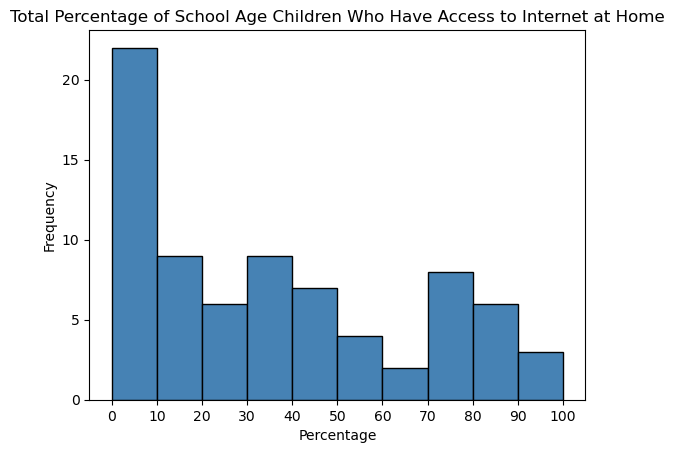

In [47]:
# Create a histogram that visualises the Total % of children who have access to internet.
# The histogram demonstrates the skewness variable above.
bins=np.arange(0,110,10)
plt.title('Total Percentage of School Age Children Who Have Access to Internet at Home')
plt.xlabel('Percentage')
plt.ylabel('Frequency')
plt.hist(mask_total, bins, edgecolor='black', color='steelblue', align='mid')
plt.xticks(bins)
plt.show() 

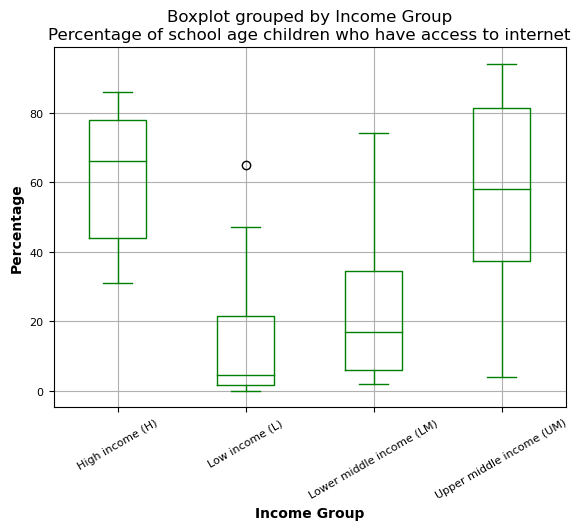

In [48]:
# A boxplot which provides a visual demonstration of the difference between income groups and their access to internt.
clean_school_df.boxplot(column='Total (%)',by='Income Group', rot=30, fontsize=8, color='green')
plt.xlabel("Income Group", weight='bold')
plt.ylabel("Percentage", weight='bold')
plt.title("Percentage of school age children who have access to internet")
plt.show()

In [49]:
# Income groups and their mean/average percentage of children who have access to internet.
clean_school_df.groupby(['Income Group']).mean(['Total (%)'])

,Total (%),Rural (Residence) (%),Urban (Residence) (%),Poorest (Wealth quintile) (%),Richest (Wealth quintile) (%)
Income Group,,,,,
High income (H),61.000000,51.600000,66.200000,30.400000,94.800000
Low income (L),13.937500,8.500000,22.250000,3.000000,33.625000
Lower middle income (LM),22.703704,13.185185,30.444444,9.259259,54.777778
Upper middle income (UM),56.571429,49.464286,64.000000,33.250000,84.214286


### 2.2 Rural versus urban access

In [50]:
# Obtaining the median value for children who have access to internet who live in rural areas
ruralMedian = clean_school_df['Rural (Residence) (%)'].median()
print(f'The median value for children who have access to internet who live in rural areas is {ruralMedian}')

The median value for children who have access to internet who live in rural areas is 14.0


In [51]:
# Obtaining the median value for children who have access to internet who live in urban areas
urbanMedian = clean_school_df['Urban (Residence) (%)'].median()
print(f'The median value for children who have access to internet who live in urban areas is {urbanMedian}')

The median value for children who have access to internet who live in urban areas is 43.5


In [52]:
# Comparing the calculated values above.
probabiltyRatio = urbanMedian/ruralMedian
print(f"Children living in urban areas are {round(probabiltyRatio,2)} times more likely to have access to internet than children living in rural areas.")

Children living in urban areas are 3.11 times more likely to have access to internet than children living in rural areas.


In [53]:
# Displaying the top 10 countries with access to internet in rural areas
topTenRural = clean_school_df.sort_values(by='Rural (Residence) (%)', ascending=False).head(10)
topTenRural

,Income Group,Total (%),Rural (Residence) (%),Urban (Residence) (%),Poorest (Wealth quintile) (%),Richest (Wealth quintile) (%)
Countries and areas,,,,,,
Dominican Republic,Upper middle income (UM),24.0,100.0,29.0,0.0,77.0
Serbia,Upper middle income (UM),94.0,91.0,97.0,71.0,100.0
North Macedonia,Upper middle income (UM),92.0,90.0,93.0,70.0,100.0
Tonga,Upper middle income (UM),91.0,90.0,94.0,83.0,95.0
Japan,High income (H),78.0,83.0,77.0,62.0,87.0
Russian Federation,Upper middle income (UM),89.0,79.0,94.0,89.0,100.0
Montenegro,Upper middle income (UM),82.0,74.0,86.0,49.0,99.0
Georgia,Upper middle income (UM),85.0,72.0,93.0,51.0,99.0
Armenia,Upper middle income (UM),81.0,71.0,88.0,47.0,99.0


In [54]:
# Displaying the top 10 countries with access to internet in urban areas
topTenUrban = clean_school_df.sort_values(by='Urban (Residence) (%)', ascending=False).head(10)
topTenUrban

,Income Group,Total (%),Rural (Residence) (%),Urban (Residence) (%),Poorest (Wealth quintile) (%),Richest (Wealth quintile) (%)
Countries and areas,,,,,,
Serbia,Upper middle income (UM),94.0,91.0,97.0,71.0,100.0
Russian Federation,Upper middle income (UM),89.0,79.0,94.0,89.0,100.0
Tonga,Upper middle income (UM),91.0,90.0,94.0,83.0,95.0
Georgia,Upper middle income (UM),85.0,72.0,93.0,51.0,99.0
North Macedonia,Upper middle income (UM),92.0,90.0,93.0,70.0,100.0
China,Upper middle income (UM),57.0,50.0,91.0,4.0,90.0
Brazil,Upper middle income (UM),83.0,51.0,89.0,84.0,97.0
Chile,High income (H),86.0,70.0,89.0,73.0,99.0
Armenia,Upper middle income (UM),81.0,71.0,88.0,47.0,99.0


In [55]:
school_df.loc[school_df['Countries and areas'] == 'Japan']

,Countries and areas,Income Group,Total (%),Rural (Residence) (%),Urban (Residence) (%),Poorest (Wealth quintile) (%),Richest (Wealth quintile) (%)
33,Japan,High income (H),78.0,83.0,77.0,62.0,87.0


In [56]:
school_df.loc[school_df['Countries and areas'] == 'Dominican Republic']

,Countries and areas,Income Group,Total (%),Rural (Residence) (%),Urban (Residence) (%),Poorest (Wealth quintile) (%),Richest (Wealth quintile) (%)
22,Dominican Republic,Upper middle income (UM),24.0,100.0,29.0,0.0,77.0


In [57]:
school_df.loc[school_df['Countries and areas'] == 'Montenegro']

,Countries and areas,Income Group,Total (%),Rural (Residence) (%),Urban (Residence) (%),Poorest (Wealth quintile) (%),Richest (Wealth quintile) (%)
46,Montenegro,Upper middle income (UM),82.0,74.0,86.0,49.0,99.0


### 2.3 The wealth gap within upper-middle-income countries

In [58]:
# Creating a mask for all countries that are classed as being in the 'Upper middle income (UM) group'
um = clean_school_df['Income Group'] == 'Upper middle income (UM)'

In [59]:
# viewing the data
umi = clean_school_df.loc[um, ]
umi

,Income Group,Total (%),Rural (Residence) (%),Urban (Residence) (%),Poorest (Wealth quintile) (%),Richest (Wealth quintile) (%)
Countries and areas,,,,,,
Algeria,Upper middle income (UM),24.0,9.0,32.0,1.0,77.0
Armenia,Upper middle income (UM),81.0,71.0,88.0,47.0,99.0
Bosnia and Herzegovina,Upper middle income (UM),59.0,51.0,76.0,8.0,96.0
Brazil,Upper middle income (UM),83.0,51.0,89.0,84.0,97.0
Bulgaria,Upper middle income (UM),76.0,66.0,81.0,35.0,97.0
China,Upper middle income (UM),57.0,50.0,91.0,4.0,90.0
Colombia,Upper middle income (UM),36.0,5.0,48.0,1.0,98.0
Costa Rica,Upper middle income (UM),72.0,61.0,78.0,46.0,99.0
Cuba,Upper middle income (UM),4.0,1.0,6.0,15.0,0.0


In [60]:
# Proportion of total data
umi.count()/clean_school_df.count()

Income Group                     0.368421
Total (%)                        0.368421
Rural (Residence) (%)            0.368421
Urban (Residence) (%)            0.368421
Poorest (Wealth quintile) (%)    0.368421
Richest (Wealth quintile) (%)    0.368421
dtype: float64

In [61]:
# Creating a cross section of upper middle income and the poorest wealth quintile
poorest = clean_school_df.loc[um, 'Poorest (Wealth quintile) (%)']

In [62]:
# Creating a cross section of upper middle income and the richest wealth quintile
richest = clean_school_df.loc[um, 'Richest (Wealth quintile) (%)']

In [63]:
# Basic descriptive statistics for the poorest wealth quintile in the upper middle income bracket
poorest.describe()

count    28.000000
mean     33.250000
std      29.725441
min       0.000000
25%       4.000000
50%      27.500000
75%      50.250000
max      89.000000
Name: Poorest (Wealth quintile) (%), dtype: float64

In [64]:
# Basic descriptive statistics for the richest wealth quintile in the upper middle income bracket
richest.describe()

count     28.000000
mean      84.214286
std       23.225716
min        0.000000
25%       77.000000
50%       94.000000
75%       99.000000
max      100.000000
Name: Richest (Wealth quintile) (%), dtype: float64

In [65]:
# viewing the data of interest
print(poorest)
print(richest)

Countries and areas
Algeria                    1.0
Armenia                   47.0
Bosnia and Herzegovina     8.0
Brazil                    84.0
Bulgaria                  35.0
China                      4.0
Colombia                   1.0
Costa Rica                46.0
Cuba                      15.0
Dominican Republic         0.0
Georgia                   51.0
Guatemala                  0.0
Iraq                      14.0
Jordan                    23.0
Maldives                  50.0
Mexico                     4.0
Montenegro                49.0
Namibia                    0.0
Russian Federation        89.0
Saint Lucia               12.0
Serbia                    71.0
Sri Lanka                 71.0
Suriname                  22.0
Thailand                  47.0
North Macedonia           70.0
Tonga                     83.0
Turkey                     2.0
Turkmenistan              32.0
Name: Poorest (Wealth quintile) (%), dtype: float64
Countries and areas
Algeria                    77.0
Armenia 

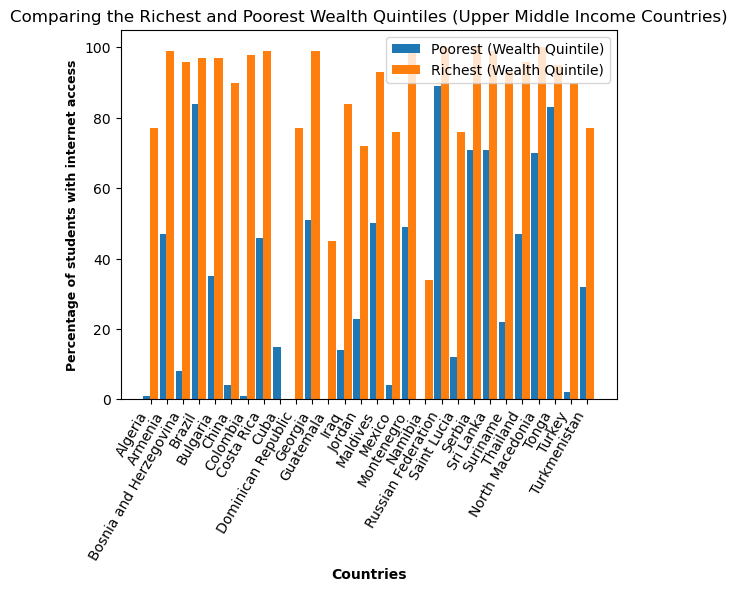

In [66]:
## Creating a bar graph which visually demonstrates the disparity between the richest and poorest quintiles in countries classified in the upper middle income group
import numpy as np 
import matplotlib.pyplot as plt 
 
# Make a data definition
country = poorest.index
poorest = poorest
richest = richest
 
X_axis = np.arange(len(country))
 
# Multi Bar Chart
plt.bar(X_axis -0.2, poorest, width=0.5, label = 'Poorest (Wealth Quintile)')
plt.bar(X_axis +0.2, richest, width=0.5, label = 'Richest (Wealth Quintile)')
 
# Xticks
plt.xticks(X_axis, country)
 
# Add labels
plt.xlabel("Countries", fontsize=10, fontweight='bold')
plt.ylabel("Percentage of students with internet access", fontsize=9, fontweight='bold')
plt.xticks(rotation=60, ha='right',fontsize=10)
plt.title('Comparing the Richest and Poorest Wealth Quintiles (Upper Middle Income Countries)')
 
# Add legend
plt.legend(loc=1)

# Display the plot
plt.show()


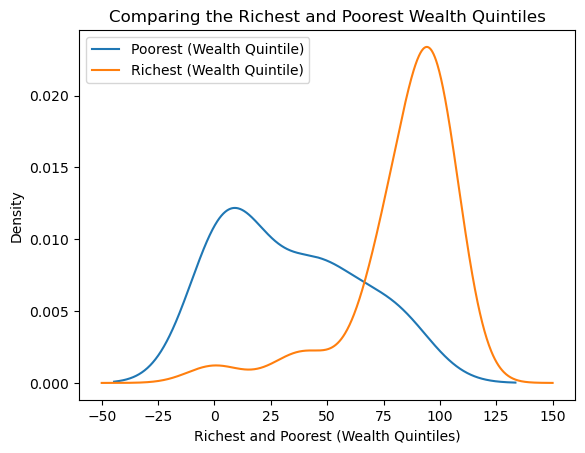

In [67]:
# A density plot to visually observe the variability of the data and compare skewness
poorest.plot.density(label = 'Poorest (Wealth Quintile)')
richest.plot.density(label = 'Richest (Wealth Quintile)')
plt.xlabel('Richest and Poorest (Wealth Quintiles)')
plt.title('Comparing the Richest and Poorest Wealth Quintiles')
plt.legend()

In [68]:
# Skewness values which quantify the visualisation above
print(f'poorest quintile {poorest.skew()}')
print(f'richest quintile {richest.skew()}')

poorest quintile 0.4654120256471673
richest quintile -2.3787251191946566


In [69]:
# obtaining more descriptive statistics to compare values between the richest and poorest quintiles
poorestMode = poorest.mode()
richestMode = richest.mode()
poorestMedian = poorest.median()
richestMedian = richest.median()
poorestKurt = poorest.kurtosis()
richestKurt = richest.kurtosis()


In [70]:
# Code to display descriptive statistics for the richest quintile
print(f'Richest Quintile Descriptive Statistics\nMode: {richestMode}\nMedian: {richestMedian}\nKurtosis: {richestKurt}')

Richest Quintile Descriptive Statistics
Mode: 0    99.0
Name: Richest (Wealth quintile) (%), dtype: float64
Median: 94.0
Kurtosis: 6.1183002921828065


In [71]:
# Code to display descriptive statistics for the poorest quintile
print(f'Poorest Quintile Descriptive Statistics\nMode: {poorestMode}\nMedian: {poorestMedian}\nKurtosis: {poorestKurt}')

Poorest Quintile Descriptive Statistics
Mode: 0    0.0
Name: Poorest (Wealth quintile) (%), dtype: float64
Median: 27.5
Kurtosis: -1.125977681360495
